In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## PREPROCESS



In [40]:
df = pd.read_excel(r'E:\Users\raphiel\Desktop\Python Practice\Tugas EVDA 1\Data Posbindu-1.xlsx')

In [41]:
print("Ukuran data awal:", df.shape)

# hapus baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Ukuran data sekarang:", df.shape)

Ukuran data awal: (323, 22)
Jumlah baris duplikat: 3
Ukuran data sekarang: (320, 22)


In [42]:
# untuk kolom Denyut Nadi yang berisi teks "na" kita jadikan kosong (NaN) dan ubah ke angka
df["Denyut Nadi (bpm)"] = pd.to_numeric(df["Denyut Nadi (bpm)"], errors="coerce")

In [45]:
# cek variasi penulisan nama kota sebelum kita seragamkan
def cek_variasi_kota(df, nama_kolom="Kota"):
    # Menghitung jumlah masing-masing variasi
    variasi_counts = df[nama_kolom].value_counts()
    
    hasil_format = [f"{kota}: {count}" for kota, count in variasi_counts.items()]
    
    # menggabungkan semua list menjadi satu string dengan pemisah koma
    hasil_akhir = ", ".join(hasil_format)
    
    # Pastikan print sejajar dengan baris di atasnya
    print(f"Total variasi penulisan: {len(variasi_counts)}")
    print(f"Dari data dengan kolom '{nama_kolom}' ini terliput: {hasil_akhir}")
    return variasi_counts

hasil_variasi_kota = cek_variasi_kota(df, "Kota")
print(hasil_variasi_kota)

Total variasi penulisan: 18
Dari data dengan kolom 'Kota' ini terliput: Jakarta: 59, Semarang: 43, Bandung: 39, Denpasar: 38, Yogyakarta: 34, Surabaya: 29, Makassar: 27, Medan: 21, Kota Denpasar: 6, SEMARANG: 3, jakarta: 3, MAKASSAR: 3, DKI Jakarta: 3, Yogya: 3, DIY Yogyakarta: 3, Kota Medan: 2, bandung: 2, Kota Bandung: 2
Kota
Jakarta           59
Semarang          43
Bandung           39
Denpasar          38
Yogyakarta        34
Surabaya          29
Makassar          27
Medan             21
Kota Denpasar      6
SEMARANG           3
jakarta            3
MAKASSAR           3
DKI Jakarta        3
Yogya              3
DIY Yogyakarta     3
Kota Medan         2
bandung            2
Kota Bandung       2
Name: count, dtype: int64


In [53]:
# menyeragamkan penulisan nama kota
def seragamkan_kota(data_kota, nama_kolom="Kota"):

    # buat daftar nama kota yang sudah diseragamkan
    daftar_kota = {
        "jakarta": "Jakarta",
        "dki jakarta": "Jakarta",

        "bandung": "Bandung",
        "kota bandung": "Bandung",

        "semarang": "Semarang",

        "denpasar": "Denpasar",
        "kota denpasar": "Denpasar",

        "yogyakarta": "Yogyakarta",
        "yogya": "Yogyakarta",
        "diy yogyakarta": "Yogyakarta",

        "surabaya": "Surabaya",

        "makassar": "Makassar",

        "medan": "Medan",
        "kota medan": "Medan"
    }

    # membersihkan penulisan nama kota
    data_kota[nama_kolom] = data_kota[nama_kolom].astype("string")
    data_kota[nama_kolom] = data_kota[nama_kolom].str.strip()
    data_kota[nama_kolom] = data_kota[nama_kolom].str.lower()

    # mengganti nama kota yang penulisannya berbeda
    data_kota[nama_kolom] = data_kota[nama_kolom].replace(daftar_kota)

    # menyeragamkan huruf kapital
    data_kota[nama_kolom] = data_kota[nama_kolom].str.title()

    # menampilkan hasil penyeragaman
    print("jumlah variasi nama kota setelah diseragamkan:",
          data_kota[nama_kolom].nunique())

    return data_kota

print(df["Kota"].value_counts())


Kota
Jakarta       65
Semarang      46
Denpasar      44
Bandung       43
Yogyakarta    40
Makassar      30
Surabaya      29
Medan         23
Name: count, dtype: Int64


Jumlah missing value:
Tanggal Lahir                  6
Tinggi Badan (cm)              6
Berat Badan (kg)               7
Lingkar Perut (cm)             9
Sistol (mmHg)                  5
Diastol (mmHg)                 5
Denyut Nadi (bpm)              3
Gula Darah Sewaktu (mg/dL)     6
Kolesterol Total (mg/dL)       6
Asam Urat (mg/dL)              7
Umur                           6
Kelompok_Usia                  6
BMI                           13
Kelompok_IMT                  13
Status_Tensi                   9
Kat_GDS                        6
Kat_Kolesterol                 6
Status_AsamUrat                7
Obesitas_Sentral               9
dtype: int64


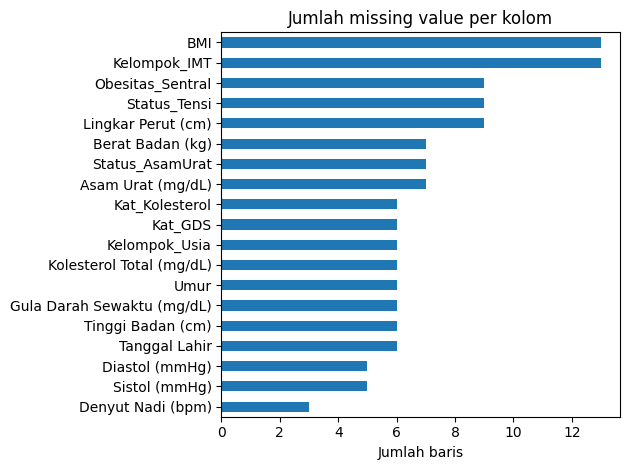

In [59]:

# membersihkan nilai yang tidak masuk akal
# nilai yang terlalu besar dianggap salah input
df.loc[df["Berat Badan (kg)"] > 500, "Berat Badan (kg)"] = np.nan
df.loc[df["Lingkar Perut (cm)"] > 500, "Lingkar Perut (cm)"] = np.nan
df.loc[df["Asam Urat (mg/dL)"] > 20, "Asam Urat (mg/dL)"] = np.nan


# mengecek missing value
kosong = df.isna().sum()
kosong = kosong[kosong > 0]

print("Jumlah missing value:")
print(kosong)


# menampilkan grafik missing value
kosong.sort_values().plot.barh(
    title="Jumlah missing value per kolom"
)
plt.xlabel("Jumlah baris")
plt.tight_layout()
plt.show()



In [ ]:

# membuat kolom umur dan kelompok usia
df["Umur"] = (pd.Timestamp("2026-10-31") - df["Tanggal Lahir"]).dt.days / 365.25

df["Kelompok_Usia"] = pd.cut(
    df["Umur"],
    bins=[0, 30, 40, 50, 60, 200],
    right=False,
    labels=["<30", "30-39", "40-49", "50-59", "60+"]
)


# membuat kolom BMI dan kelompok IMT
df["BMI"] = df["Berat Badan (kg)"] / (df["Tinggi Badan (cm)"] / 100) ** 2

df["Kelompok_IMT"] = pd.cut(
    df["BMI"],
    bins=[0, 18.5, 23, 25, 100],
    right=False,
    labels=["Kurus", "Normal", "Overweight", "Obesitas"]
)


# membuat kategori kesehatan
sis = df["Sistol (mmHg)"]
dia = df["Diastol (mmHg)"]
au = df["Asam Urat (mg/dL)"]
lp = df["Lingkar Perut (cm)"]

lk = df["Jenis Kelamin"] == "L"
pr = df["Jenis Kelamin"] == "P"


# menentukan status tekanan darah
df["Status_Tensi"] = "Normal"
df.loc[(sis >= 140) | (dia >= 90), "Status_Tensi"] = "Hipertensi"
df.loc[sis.isna() | dia.isna(), "Status_Tensi"] = np.nan


# menentukan kategori gula darah
df["Kat_GDS"] = pd.cut(
    df["Gula Darah Sewaktu (mg/dL)"],
    bins=[0, 140, 200, 1000],
    right=False,
    labels=["Normal", "Pradiabetes", "Diabetes"]
)


# menentukan kategori kolesterol
df["Kat_Kolesterol"] = pd.cut(
    df["Kolesterol Total (mg/dL)"],
    bins=[0, 200, 240, 1000],
    right=False,
    labels=["Normal", "Borderline", "Tinggi"]
)


# menentukan status asam urat berdasarkan jenis kelamin
df["Status_AsamUrat"] = "Normal"
df.loc[(lk & (au >= 7.0)) | (pr & (au >= 6.0)), "Status_AsamUrat"] = "Hiperurikemia"
df.loc[au.isna(), "Status_AsamUrat"] = np.nan


# menentukan status obesitas sentral
df["Obesitas_Sentral"] = "Tidak"
df.loc[(lk & (lp >= 90)) | (pr & (lp >= 80)), "Obesitas_Sentral"] = "Ya"
df.loc[lp.isna(), "Obesitas_Sentral"] = np.nan


# mengecek hasil preprocessing
print("Ukuran data akhir:", df.shape)

for kolom in [
    "Status_Tensi",
    "Kat_GDS",
    "Kat_Kolesterol",
    "Status_AsamUrat",
    "Obesitas_Sentral",
    "Kelompok_IMT",
    "Kelompok_Usia"
]:
    print("\n", kolom)
    print(df[kolom].value_counts(dropna=False))


# menyimpan data yang sudah dibersihkan
df.to_excel("Data_Posbindu_bersih.xlsx", index=False)
print("Data bersih disimpan: Data_Posbindu_bersih.xlsx")

Ukuran data akhir: (320, 31)

 Status_Tensi
Status_Tensi
Normal        299
Hipertensi     12
NaN             9
Name: count, dtype: int64

 Kat_GDS
Kat_GDS
Normal         224
Pradiabetes     59
Diabetes        31
NaN              6
Name: count, dtype: int64

 Kat_Kolesterol
Kat_Kolesterol
Normal        229
Borderline     83
NaN             6
Tinggi          2
Name: count, dtype: int64

 Status_AsamUrat
Status_AsamUrat
Normal           266
Hiperurikemia     47
NaN                7
Name: count, dtype: int64

 Obesitas_Sentral
Obesitas_Sentral
Tidak    210
Ya       101
NaN        9
Name: count, dtype: int64

 Kelompok_IMT
Kelompok_IMT
Obesitas      137
Normal         87
Overweight     53
Kurus          30
NaN            13
Name: count, dtype: int64

 Kelompok_Usia
Kelompok_Usia
50-59    79
40-49    79
60+      68
30-39    54
<30      34
NaN       6
Name: count, dtype: int64
Data berhasil disimpan: Data_Posbindu_bersih.xlsx
